In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [ ]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

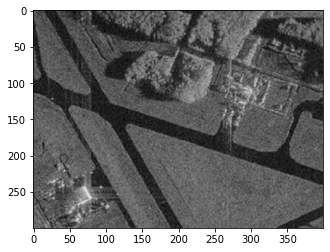

In [ ]:
plt.imshow(image_gray, cmap="gray")

# Алгоритм разрастания регионов

In [ ]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False


In [ ]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask

    return mask*255


In [ ]:
seed_point = (250,250)
mask = region_growing(image_gray,seed_point,homo_average,1, 10)

3
4
4
5
7
6
6
9
7
6
6
9
13
12
15
17
13
13
16
16
14
16
15
16
10
11
14
13
14
10
10
14
17
15
36
22
21
18
21
21
25
23
43
31
34
23
20
27
29
35
40
32
35
42
48
52
30
23
20
19
19
20
18
22
74
24
26
29
30
27
29
29
28
29
20
17
17
21
20
25
23
24
20
18
19
15
18
18
15
18
13
10
9
7
9
9
10
11
12
10
12
11
8
9
7
4
3
6
6
6
5
5
5
3
2
2
2
1
0


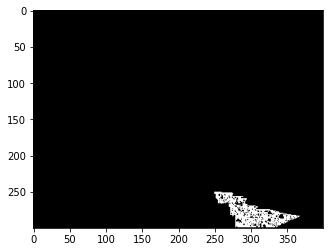

In [ ]:
plt.imshow(mask, cmap="gray")

# K-means

In [ ]:
# Define criteria = ( type, max_iter = 10 , epsilon = 1.0 )
# criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 10, 1.0)

In [ ]:
flags = cv2.KMEANS_RANDOM_CENTERS

In [ ]:
z = image_gray.reshape((-1,3))
# convert to np.float32
z = np.float32(z)
# define criteria, number of clusters(K) and apply kmeans()
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
K = 3
ret,label,center=cv2.kmeans(z,K,None,criteria,10,cv2.KMEANS_RANDOM_CENTERS)
# Now convert back into uint8, and make original image
center = np.uint8(center)
res = center[label.flatten()]
res2 = res.reshape((image_gray.shape))

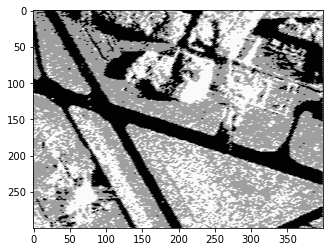

In [ ]:
plt.imshow(res2, cmap="gray")

# Watershed+Distance transform

In [ ]:
image = cv2.imread('oranges_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

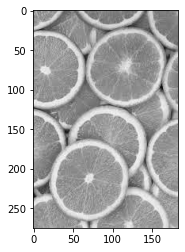

In [ ]:
plt.imshow(image_gray, cmap="gray")

In [ ]:
ret, thresh = cv2.threshold(image_gray,0,255, cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)

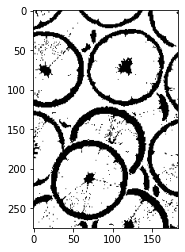

In [ ]:
plt.imshow(thresh, cmap="gray")

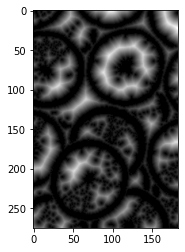

In [ ]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
plt.imshow(dist, cmap="gray")

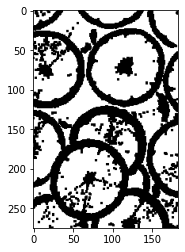

In [ ]:
ret, sure_fg = cv2.threshold(dist, 0.1 * dist.max(), 255, cv2.THRESH_BINARY)
plt.imshow(sure_fg, cmap="gray")

In [ ]:
sure_fg = sure_fg.astype(np.uint8)

In [ ]:
ret, markers = cv2.connectedComponents(sure_fg)

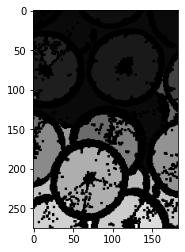

In [ ]:
plt.imshow(markers, cmap="gray")

In [ ]:
markers = cv2.watershed(image, markers)

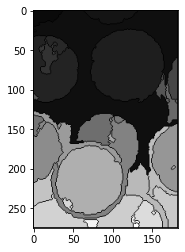

In [ ]:
plt.imshow(markers, cmap="gray")

In [ ]:
# ДЗ
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

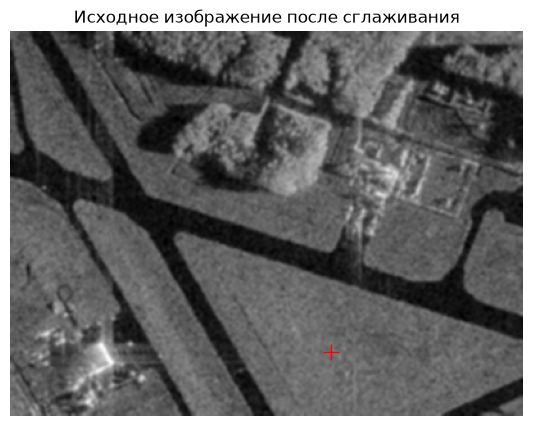

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('sar_1.jpg')

if image is None:
    raise FileNotFoundError("Положите картинку рядом с ноутбуком")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_gray = cv2.GaussianBlur(image_gray, (5, 5), 1)

plt.figure(figsize=(7, 5))
plt.imshow(image_gray, cmap='gray')
plt.plot(250, 250, 'r+', markersize=12)
plt.title('Исходное изображение после сглаживания')
plt.axis('off')
plt.show()

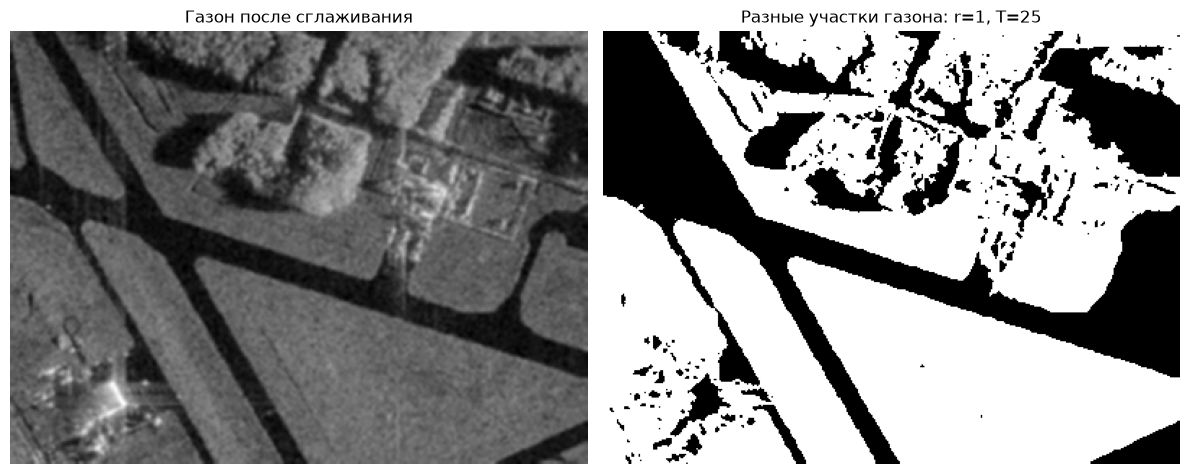

Площадь по среднему: 79382 пикселей


In [3]:
# 1. Критерий средней яркости и разрастание региона

def homo_average(img, mask, T):
    average = np.mean(img[mask > 0])
    return np.abs(img - average) <= T


def region_growing(image, seed_point, homo_fun, r, T):
    image = image.astype(np.float32)
    mask = np.zeros(image.shape, dtype=np.uint8)

    if isinstance(seed_point, tuple):
        seed_points = [seed_point]
    else:
        seed_points = seed_point

    for point in seed_points:
        mask[point[1], point[0]] = 1

    kernel = np.ones((2 * r + 1, 2 * r + 1), dtype=np.uint8)

    while True:
        neighbors = (cv2.dilate(mask, kernel) > 0) & (mask == 0)
        new_pixels = neighbors & homo_fun(image, mask, T)

        if not np.any(new_pixels):
            break

        mask[new_pixels] = 1

    return mask * 255


seed_point = [(250, 250), (220, 110), (75, 40), (190, 35),
              (150, 280), (155, 210), (140, 220), (50, 130),
              (20, 265), (298, 295)]

r = 1
T = 25

mask_avg = region_growing(image_gray, seed_point, homo_average, r, T)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image_gray, cmap='gray')
axes[0].set_title('Газон после сглаживания')

axes[1].imshow(mask_avg, cmap='gray')
axes[1].set_title(f'Разные участки газона: r={r}, T={T}')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Площадь по среднему:', np.sum(mask_avg > 0), 'пикселей')

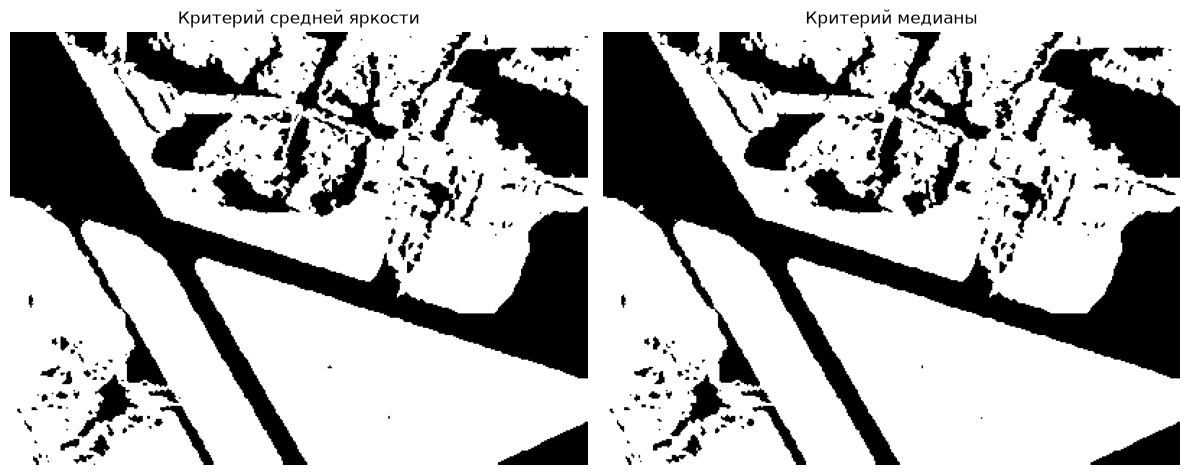

Площадь по среднему: 79382 пикселей
Площадь по медиане: 79872 пикселей


In [4]:
def homo_median(img, mask, T):
    median = np.median(img[mask > 0])
    return np.abs(img - median) <= T


mask_median = region_growing(
    image_gray, seed_point, homo_median, r, T
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(mask_avg, cmap='gray')
axes[0].set_title('Критерий средней яркости')

axes[1].imshow(mask_median, cmap='gray')
axes[1].set_title('Критерий медианы')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Площадь по среднему:', np.sum(mask_avg > 0), 'пикселей')
print('Площадь по медиане:', np.sum(mask_median > 0), 'пикселей')

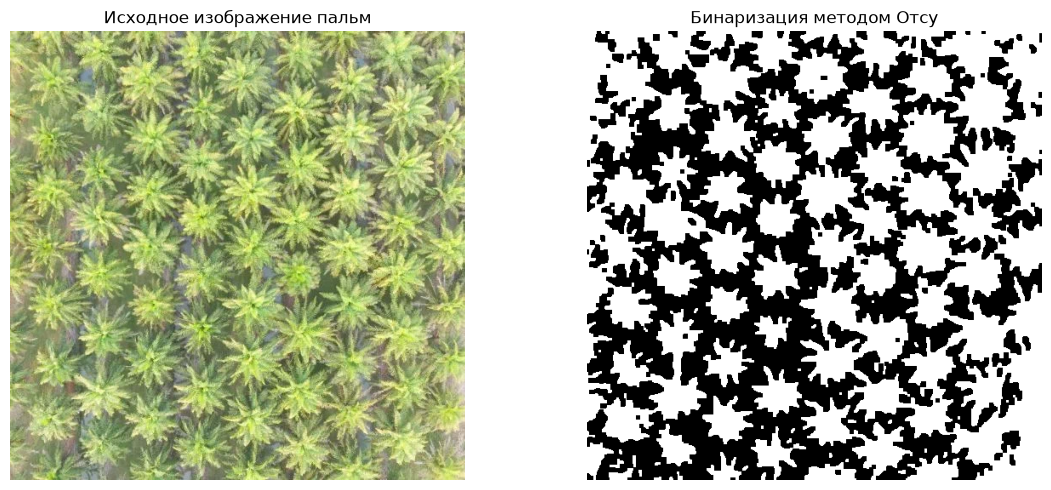

Порог Отсу: 157.0


In [6]:
palm = cv2.imread('palm_1.JPG')

if palm is None:
    raise FileNotFoundError("Изображение palm_1.JPG не найдено")

palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)
palm_gray = cv2.GaussianBlur(palm_gray, (5, 5), 1)

T_otsu, thresh = cv2.threshold(
    palm_gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

kernel = np.ones((3, 3), dtype=np.uint8)

thresh = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel
)

thresh = cv2.morphologyEx(
    thresh, cv2.MORPH_CLOSE,
    np.ones((5, 5), dtype=np.uint8)
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(palm, cv2.COLOR_BGR2RGB))
plt.title('Исходное изображение пальм')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Бинаризация методом Отсу')
plt.axis('off')

plt.tight_layout()
plt.show()

print('Порог Отсу:', T_otsu)

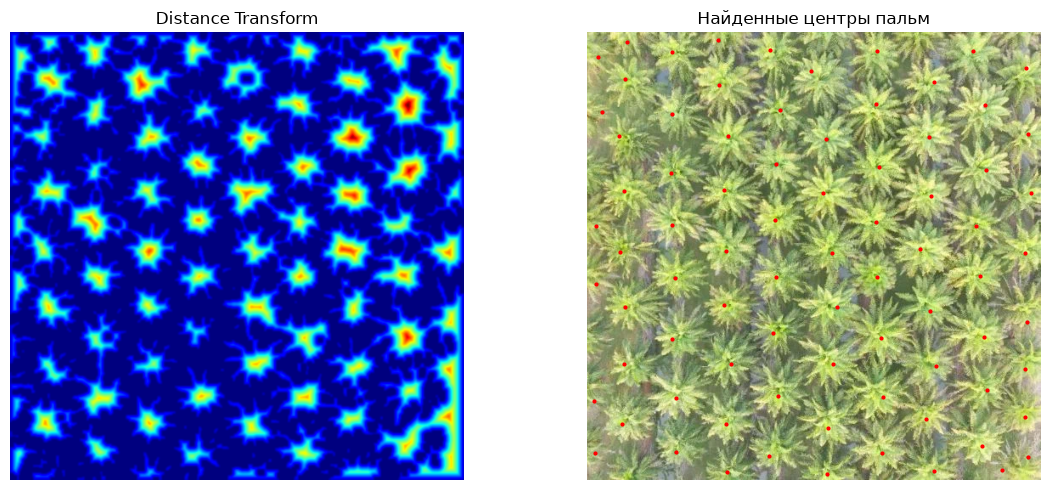

Количество найденных центров: 80


In [7]:
bordered = cv2.copyMakeBorder(
    thresh, 1, 1, 1, 1,
    cv2.BORDER_CONSTANT, value=0
)

dist = cv2.distanceTransform(
    bordered, cv2.DIST_L2, 5
)[1:-1, 1:-1]

dist = cv2.GaussianBlur(dist, (5, 5), 1)

local_max = cv2.dilate(
    dist, np.ones((31, 31), dtype=np.uint8)
)

sure_fg = np.uint8(
    (dist == local_max) & (dist > 7)
) * 255

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(dist, cmap='jet')
axes[0].set_title('Distance Transform')

axes[1].imshow(cv2.cvtColor(palm, cv2.COLOR_BGR2RGB))

y, x = np.where(sure_fg > 0)
axes[1].plot(x, y, 'r.', markersize=4)
axes[1].set_title('Найденные центры пальм')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Количество найденных центров:', len(x))

Автоматическая оценка числа пальм: 80


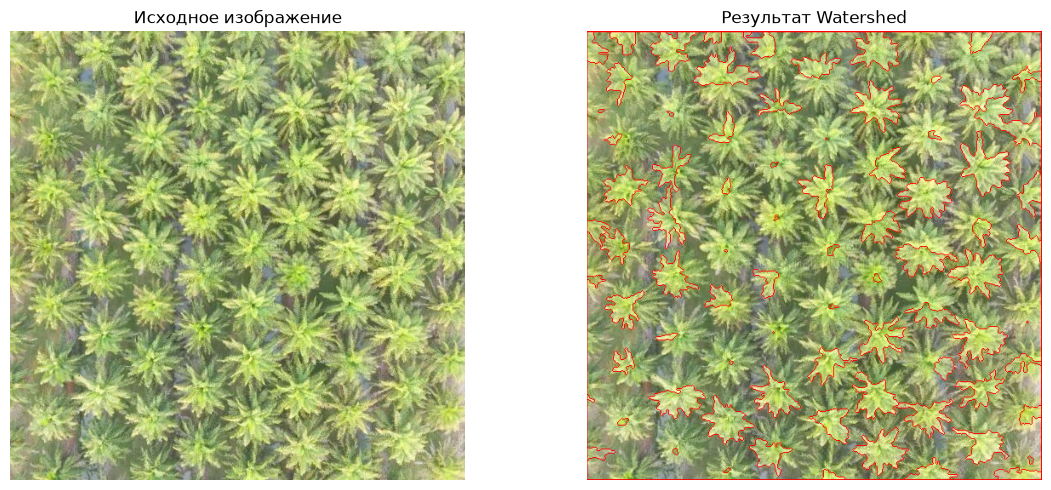

In [9]:
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1

sure_bg = cv2.dilate(thresh, kernel, iterations=2)
unknown = cv2.subtract(sure_bg, sure_fg)

markers[unknown == 255] = 0

markers = cv2.watershed(
    cv2.GaussianBlur(palm, (5, 5), 1),
    markers
)

palm_labels = np.unique(markers[markers > 1])
palm_count = len(palm_labels)

print('Автоматическая оценка числа пальм:', palm_count)

result = palm.copy()
result[markers == -1] = [0, 0, 255]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(cv2.cvtColor(palm, cv2.COLOR_BGR2RGB))
axes[0].set_title('Исходное изображение')

axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[1].set_title('Результат Watershed')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()